In [1]:
import numpy as np
import os
import glob
try:
    from google.colab import drive
    drive.mount('/content/drive')
    colab_dir = "/content/drive/MyDrive/ColabNotebooks/Noron&DeepLearning/techtrail-ai-engine-v1"
    if os.path.exists(colab_dir):
        %cd {colab_dir}
except Exception:
    pass

print("Đường dẫn làm việc hiện tại:", os.getcwd())
print("Danh sách file trong data/:", os.listdir('data') if os.path.exists('data') else "Chưa có thư mục data")

Mounted at /content/drive
/content/drive/.shortcut-targets-by-id/1MbEYfOnGLjsiwuZDnQXcvizGSO-YHvP9/Noron&DeepLearning/techtrail-ai-engine-v1
Đường dẫn làm việc hiện tại: /content/drive/.shortcut-targets-by-id/1MbEYfOnGLjsiwuZDnQXcvizGSO-YHvP9/Noron&DeepLearning/techtrail-ai-engine-v1
Danh sách file trong data/: ['resume-dataset.csv', 'train.csv', 'val.csv', 'test.csv', 'v2', 'train_cleaned.csv', 'val_cleaned.csv', 'test_cleaned.csv']


In [2]:
import os

os.chdir('/content/drive/.shortcut-targets-by-id/1MbEYfOnGLjsiwuZDnQXcvizGSO-YHvP9/Noron&DeepLearning/techtrail-ai-engine-v1')

if not os.path.exists('data'):
    os.makedirs('data')
    print("Đã tự động tạo thư mục 'data'.")
else:
    print("Thư mục 'data' đã tồn tại.")

print("Các file/thư mục hiện tại:", os.listdir('.'))

Thư mục 'data' đã tồn tại.
Các file/thư mục hiện tại: ['.git', '.gitignore', 'README.md', '__pycache__', 'results', 'data', 'processed', 'models', 'evaluation.py']


## Chia data thành 70-15-15: train-test-validation


In [3]:
%cd "/content/drive/MyDrive/ColabNotebooks/Noron&DeepLearning/techtrail-ai-engine-v1"
import os
print(os.listdir('data'))

/content/drive/.shortcut-targets-by-id/1MbEYfOnGLjsiwuZDnQXcvizGSO-YHvP9/Noron&DeepLearning/techtrail-ai-engine-v1
['resume-dataset.csv', 'train.csv', 'val.csv', 'test.csv', 'v2', 'train_cleaned.csv', 'val_cleaned.csv', 'test_cleaned.csv']


In [4]:
import os, re, json, pandas as pd, nltk
from nltk.corpus import stopwords
from sklearn.model_selection import train_test_split
from collections import Counter

nltk.download('stopwords', quiet=True)
stop_words = set(stopwords.words('english'))

def clean_text(text, category="", min_len=2):
    text = re.sub(r'<[^>]+>', ' ', str(text))
    for part in re.split(r'[()/]', str(category)):
        if part.strip():
            text = re.sub(re.escape(part.strip()), ' ', text, flags=re.IGNORECASE)
    text = re.sub(r'[^a-z\s]', ' ', text.lower())
    return " ".join(w for w in text.split() if w not in stop_words and len(w) > min_len)


df = pd.read_csv('data/resume-dataset.csv')
df = df[['Resume', 'Category']].rename(columns={'Resume': 'text_sequence', 'Category': 'label'})


df['clean_text'] = df.apply(lambda r: clean_text(r['text_sequence'], r['label']), axis=1)


before = len(df)
df = df.drop_duplicates(subset='clean_text').reset_index(drop=True)
print(f"Đã xóa {before - len(df)} dòng trùng (theo clean_text) -> còn {len(df)}")

df['id'] = df.index


train_df, temp_df = train_test_split(df, test_size=0.3, random_state=42, stratify=df['label'])
val_df, test_df   = train_test_split(temp_df, test_size=0.5, random_state=42, stratify=temp_df['label'])


cols = ['id', 'label', 'text_sequence', 'clean_text']
train_df[cols].to_csv('data/train_cleaned.csv', index=False)
val_df[cols].to_csv('data/val_cleaned.csv', index=False)
test_df[cols].to_csv('data/test_cleaned.csv', index=False)

print(f"Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")


train_set, val_set, test_set = set(train_df['clean_text']), set(val_df['clean_text']), set(test_df['clean_text'])
print("Trùng train-val:", len(train_set & val_set))
print("Trùng train-test:", len(train_set & test_set))
print("Trùng val-test:", len(val_set & test_set))

Đã xóa 0 dòng trùng (theo clean_text) -> còn 2000
Train: 1400 | Val: 300 | Test: 300
Trùng train-val: 0
Trùng train-test: 0
Trùng val-test: 0


## Làm sạch dữ liệu (task Vinh)


In [5]:
train_df = pd.read_csv('data/train_cleaned.csv')
word_counts = Counter(" ".join(train_df['clean_text'].fillna("")).split())

vocab = {'<PAD>': 0, '<UNK>': 1}
for word, freq in word_counts.items():
    if freq >= 2:
        vocab[word] = len(vocab)

os.makedirs('processed', exist_ok=True)
with open('processed/vocab.json', 'w') as f:
    json.dump(vocab, f, indent=2)

print(f"Vocab size: {len(vocab)}")

Vocab size: 1000


In [6]:
import joblib
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import classification_report

train, val, test = [pd.read_csv(f'data/{s}_cleaned.csv').fillna('') for s in ['train', 'val', 'test']]

model = make_pipeline(
    TfidfVectorizer(max_features=5000, ngram_range=(1, 2)),
    LogisticRegression(max_iter=1000, class_weight='balanced')
)
model.fit(train['clean_text'], train['label'])

for name, df in [('Val', val), ('Test', test)]:
    y_pred = model.predict(df['clean_text'])
    print(f"\n=== {name} Classification Report ===")
    print(classification_report(df['label'], y_pred))

os.makedirs('models', exist_ok=True)
joblib.dump(model, 'models/baseline_pipeline.pkl')


=== Val Classification Report ===
                                    precision    recall  f1-score   support

                 Backend Developer       0.67      0.76      0.72        38
                     Cloud Enginee       0.89      0.82      0.85        38
                    Data Scientist       0.85      0.89      0.87        37
                Frontend Developer       0.72      0.76      0.74        37
              Full Stack Developer       0.76      0.68      0.71        37
         Machine Learning Engineer       0.86      0.82      0.84        38
Mobile App Developer (iOS/Android)       0.91      0.86      0.89        37
                  Python Developer       0.75      0.79      0.77        38

                          accuracy                           0.80       300
                         macro avg       0.80      0.80      0.80       300
                      weighted avg       0.80      0.80      0.80       300


=== Test Classification Report ===
              

['models/baseline_pipeline.pkl']

In [7]:
%%writefile evaluation.py
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, precision_recall_fscore_support)

METRIC_COLS = ['accuracy', 'precision_macro', 'recall_macro', 'f1_macro']


def compute_metrics(y_true, y_pred):
    """Accuracy, Precision/Recall/F1 (macro)."""
    p, r, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average='macro', zero_division=0)
    return {
        'accuracy': float(accuracy_score(y_true, y_pred)),
        'precision_macro': float(p),
        'recall_macro': float(r),
        'f1_macro': float(f1),
    }


def per_class_report(y_true, y_pred, labels=None):
    """Bảng precision / recall / f1 / support cho từng lớp."""
    p, r, f1, s = precision_recall_fscore_support(
        y_true, y_pred, labels=labels, average=None, zero_division=0)
    index = labels if labels is not None else sorted(set(y_true) | set(y_pred))
    return pd.DataFrame({'precision': p, 'recall': r, 'f1': f1, 'support': s},
                        index=index)


def plot_confusion_matrix(y_true, y_pred, labels, title='Confusion Matrix',
                          normalize=True, save_path=None, figsize=(10, 8)):
    """Vẽ confusion matrix (mặc định chuẩn hóa theo hàng = recall từng lớp)."""
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    cm_show = cm.astype(float)
    if normalize:
        cm_show = cm_show / np.maximum(cm_show.sum(axis=1, keepdims=True), 1)

    fig, ax = plt.subplots(figsize=figsize)
    im = ax.imshow(cm_show, cmap='Blues')
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    ax.set_xticks(range(len(labels)))
    ax.set_yticks(range(len(labels)))
    ax.set_xticklabels(labels, rotation=45, ha='right')
    ax.set_yticklabels(labels)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
    ax.set_title(title)
    thresh = cm_show.max() / 2 if cm_show.size else 0
    for i in range(len(labels)):
        for j in range(len(labels)):
            txt = f'{cm_show[i, j]:.2f}' if normalize else f'{int(cm[i, j])}'
            ax.text(j, i, txt, ha='center', va='center', fontsize=8,
                    color='white' if cm_show[i, j] > thresh else 'black')
    fig.tight_layout()
    if save_path:
        os.makedirs(os.path.dirname(save_path) or '.', exist_ok=True)
        fig.savefig(save_path, dpi=150)
    plt.show()
    return cm


def most_confused_pairs(y_true, y_pred, labels, top_k=10):
    """Các cặp (lớp thật -> lớp dự đoán sai) hay nhầm nhất, phục vụ error analysis."""
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    rows = [(labels[i], labels[j], int(cm[i, j]))
            for i in range(len(labels)) for j in range(len(labels))
            if i != j and cm[i, j] > 0]
    df = pd.DataFrame(rows, columns=['true_label', 'pred_label', 'count'])
    return df.sort_values('count', ascending=False).head(top_k).reset_index(drop=True)


def save_predictions(path, ids, y_true, y_pred):
    """Lưu dự đoán theo quy ước: id, y_true, y_pred."""
    os.makedirs(os.path.dirname(path) or '.', exist_ok=True)
    pd.DataFrame({'id': list(ids), 'y_true': list(y_true),
                  'y_pred': list(y_pred)}).to_csv(path, index=False)


def load_predictions(path):
    """Đọc file dự đoán, trả về DataFrame có cột id, y_true, y_pred."""
    df = pd.read_csv(path)
    missing = {'id', 'y_true', 'y_pred'} - set(df.columns)
    if missing:
        raise ValueError(f'{path} thiếu cột: {sorted(missing)}')
    return df


def evaluate_model(name, y_true, y_pred, labels, out_dir='results',
                   plot=True, normalize=True):
    """Đánh giá đầy đủ 1 mô hình: in report, vẽ/lưu confusion matrix, lưu metrics JSON."""
    metrics = compute_metrics(y_true, y_pred)
    print(f'\n=== {name} ===')
    print(classification_report(y_true, y_pred, labels=labels, zero_division=0))
    print('Tổng hợp:', {k: round(v, 4) for k, v in metrics.items()})

    os.makedirs(out_dir, exist_ok=True)
    with open(os.path.join(out_dir, f'{name}_metrics.json'), 'w') as f:
        json.dump(metrics, f, indent=2)
    per_class_report(y_true, y_pred, labels).to_csv(
        os.path.join(out_dir, f'{name}_per_class.csv'))
    if plot:
        plot_confusion_matrix(
            y_true, y_pred, labels, title=f'Confusion Matrix - {name}',
            normalize=normalize,
            save_path=os.path.join(out_dir, f'{name}_confusion_matrix.png'))
    return metrics


def compare_models(results):
    """
    results: {tên mô hình: (y_true, y_pred)}
    Trả về bảng so sánh Accuracy / Precision / Recall / F1-macro.
    """
    rows = {name: compute_metrics(yt, yp) for name, (yt, yp) in results.items()}
    return pd.DataFrame(rows).T[METRIC_COLS]


def plot_comparison(comp_df, title='So sánh hiệu năng mô hình', save_path=None):
    """Biểu đồ cột nhóm cho bảng so sánh từ compare_models()."""
    ax = comp_df.plot(kind='bar', figsize=(9, 5), rot=0)
    ax.set_ylim(0, 1.05)
    ax.set_ylabel('Score')
    ax.set_title(title)
    ax.legend(loc='lower right')
    for c in ax.containers:
        ax.bar_label(c, fmt='%.2f', fontsize=8)
    plt.tight_layout()
    if save_path:
        os.makedirs(os.path.dirname(save_path) or '.', exist_ok=True)
        plt.savefig(save_path, dpi=150)
    plt.show()

Overwriting evaluation.py



=== baseline_val ===
                                    precision    recall  f1-score   support

                 Backend Developer       0.67      0.76      0.72        38
                     Cloud Enginee       0.89      0.82      0.85        38
                    Data Scientist       0.85      0.89      0.87        37
                Frontend Developer       0.72      0.76      0.74        37
              Full Stack Developer       0.76      0.68      0.71        37
         Machine Learning Engineer       0.86      0.82      0.84        38
Mobile App Developer (iOS/Android)       0.91      0.86      0.89        37
                  Python Developer       0.75      0.79      0.77        38

                          accuracy                           0.80       300
                         macro avg       0.80      0.80      0.80       300
                      weighted avg       0.80      0.80      0.80       300

Tổng hợp: {'accuracy': 0.7967, 'precision_macro': 0.8009, 'reca

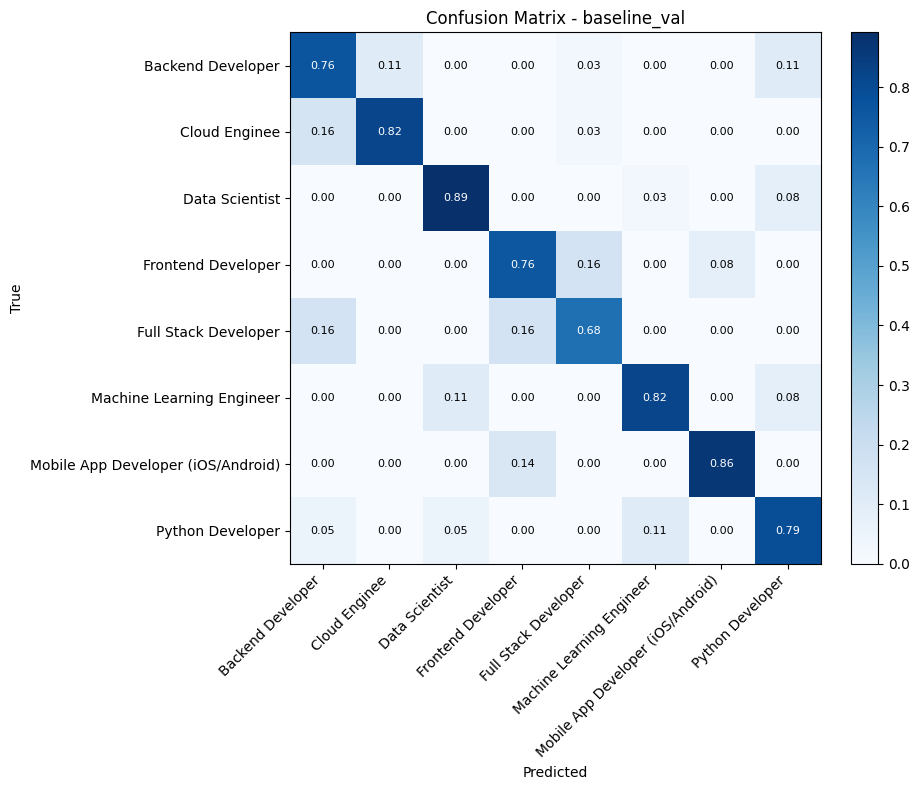


=== baseline_test ===
                                    precision    recall  f1-score   support

                 Backend Developer       0.74      0.84      0.78        37
                     Cloud Enginee       0.94      0.84      0.89        37
                    Data Scientist       0.78      0.84      0.81        38
                Frontend Developer       0.74      0.84      0.79        38
              Full Stack Developer       0.87      0.68      0.76        38
         Machine Learning Engineer       0.83      0.81      0.82        37
Mobile App Developer (iOS/Android)       0.89      0.87      0.88        38
                  Python Developer       0.76      0.78      0.77        37

                          accuracy                           0.81       300
                         macro avg       0.82      0.81      0.81       300
                      weighted avg       0.82      0.81      0.81       300

Tổng hợp: {'accuracy': 0.8133, 'precision_macro': 0.8197, 'rec

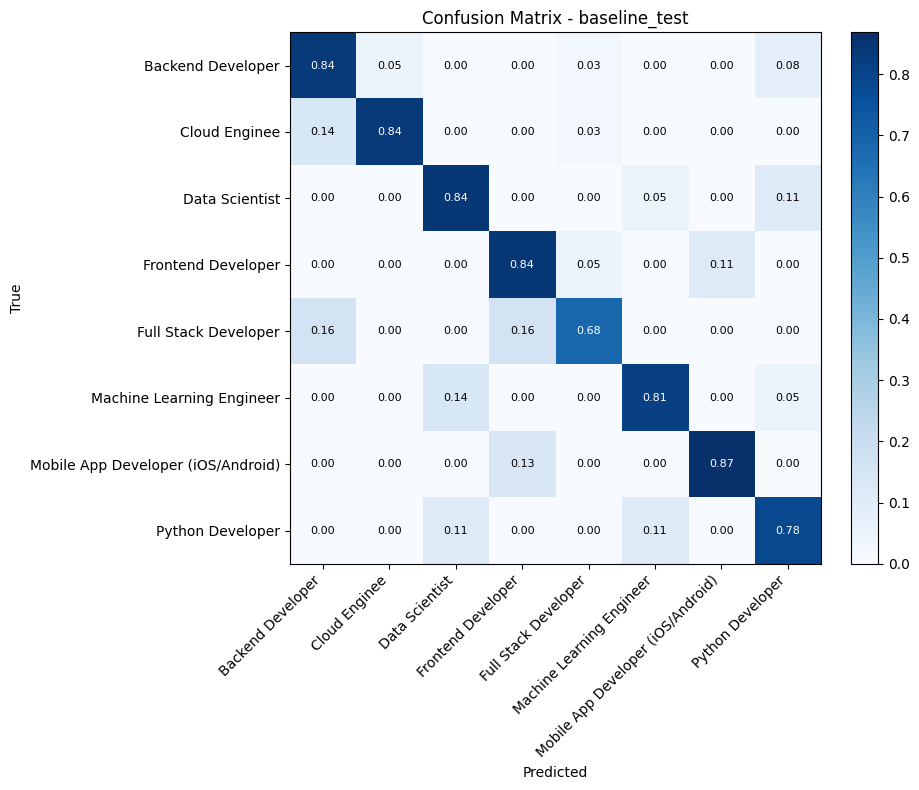

In [8]:
import importlib, joblib
import evaluation
importlib.reload(evaluation)
from evaluation import (evaluate_model, compare_models, plot_comparison,
                        most_confused_pairs, save_predictions, load_predictions)

val  = pd.read_csv('data/val_cleaned.csv').fillna('')
test = pd.read_csv('data/test_cleaned.csv').fillna('')

baseline = joblib.load('models/baseline_pipeline.pkl')
labels = list(baseline.classes_)

baseline_metrics = {}
baseline_preds = {}
for split_name, split_df in [('val', val), ('test', test)]:
    y_pred = baseline.predict(split_df['clean_text'])
    baseline_preds[split_name] = y_pred
    baseline_metrics[split_name] = evaluate_model(
        f'baseline_{split_name}', split_df['label'], y_pred, labels)
    save_predictions(f'results/baseline_{split_name}_preds.csv',
                     split_df['id'], split_df['label'], y_pred)

In [9]:
confused = most_confused_pairs(test['label'], baseline_preds['test'], labels, top_k=10)
confused.to_csv('results/baseline_test_confused_pairs.csv', index=False)
confused

,true_label,pred_label,count
0,Full Stack Developer,Frontend Developer,6
1,Full Stack Developer,Backend Developer,6
2,Cloud Enginee,Backend Developer,5
3,Machine Learning Engineer,Data Scientist,5
4,Mobile App Developer (iOS/Android),Frontend Developer,5
5,Data Scientist,Python Developer,4
6,Python Developer,Data Scientist,4
7,Frontend Developer,Mobile App Developer (iOS/Android),4
8,Python Developer,Machine Learning Engineer,4
9,Backend Developer,Python Developer,3


In [10]:
tfidf = baseline.steps[0][1]
clf = baseline.steps[-1][1]
feature_names = tfidf.get_feature_names_out()

rows = []
for cls, coefs in zip(clf.classes_, clf.coef_):
    top_idx = coefs.argsort()[::-1][:10]
    rows.append({'label': cls, 'top_terms': ', '.join(feature_names[top_idx])})

top_terms_df = pd.DataFrame(rows)
top_terms_df.to_csv('results/baseline_top_terms.csv', index=False)
pd.set_option('display.max_colwidth', None)
top_terms_df

,label,top_terms
0,Backend Developer,"growing, authentication, contract, jobs, batch, batch jobs, duplicate, shared, everything, peak"
1,Cloud Enginee,"deployments, cloud, environment, azure, terraform, secrets, vault, server provisioning, delaying, delaying new"
2,Data Scientist,"survey, behavioral, model, logs, test, data needed, survey data, reconciled behavioral, behavioral data, data product"
3,Frontend Developer,"state, component, animations, lost user, page refreshed, user input, whenever page, input whenever, form lost, input"
4,Full Stack Developer,"api, feature, end, database, api layer, frontend, server, client, backend, small team"
5,Machine Learning Engineer,"model, training, inference, reviewers, tensorflow, gpus, specific, domain specific, domain, underrepresented"
6,Mobile App Developer (iOS/Android),"logic, sizes, location, onboarding flow, duplicated codebases, notifications, duplicated, shared business, codebases, business logic"
7,Python Developer,"scripts, every, steps, automation, daily, legacy, whenever upstream, upstream api, tool broke, upstream"


Chưa có results/lstm_attention_test_preds.csv -> tạm thời chỉ hiển thị baseline.


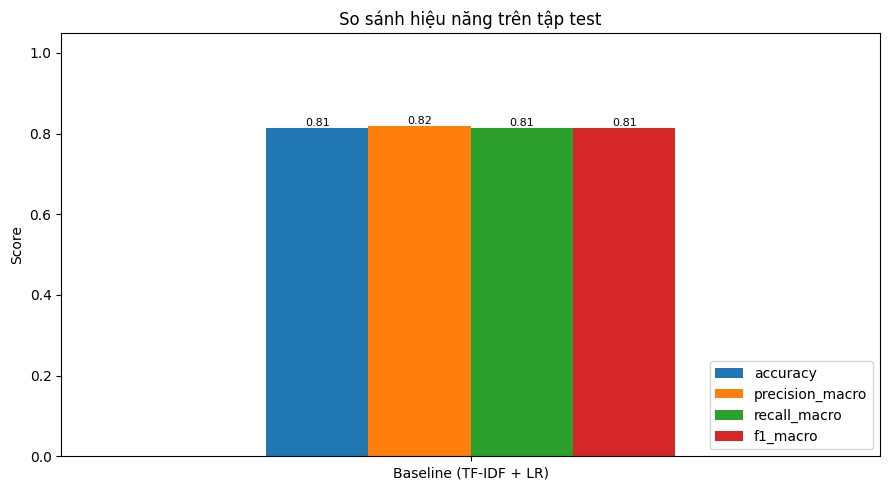

,accuracy,precision_macro,recall_macro,f1_macro
Baseline (TF-IDF + LR),0.8133,0.8197,0.8134,0.8138


In [11]:
results = {'Baseline (TF-IDF + LR)': (test['label'], baseline_preds['test'])}

lstm_path = 'results/lstm_attention_test_preds.csv'
if os.path.exists(lstm_path):
    lp = load_predictions(lstm_path)
    merged = test[['id', 'label']].merge(lp[['id', 'y_pred']], on='id', how='inner')
    if len(merged) != len(test):
        print(f"Cảnh báo: chỉ khớp {len(merged)}/{len(test)} dòng theo id giữa test và file dự đoán LSTM")
    results['LSTM + Attention'] = (merged['label'], merged['y_pred'])
else:
    print(f"Chưa có {lstm_path} -> tạm thời chỉ hiển thị baseline.")

comparison = compare_models(results)
comparison.round(4).to_csv('results/model_comparison.csv')
plot_comparison(comparison, title='So sánh hiệu năng trên tập test',
                save_path='results/model_comparison.png')
comparison.round(4)


=== baseline_fulltext_v1 ===
                                    precision    recall  f1-score   support

                 Backend Developer       0.72      0.84      0.78        37
                     Cloud Enginee       0.94      0.84      0.89        37
                    Data Scientist       0.78      0.84      0.81        38
                Frontend Developer       0.74      0.84      0.79        38
              Full Stack Developer       0.87      0.68      0.76        38
         Machine Learning Engineer       0.83      0.81      0.82        37
Mobile App Developer (iOS/Android)       0.89      0.87      0.88        38
                  Python Developer       0.76      0.76      0.76        37

                          accuracy                           0.81       300
                         macro avg       0.82      0.81      0.81       300
                      weighted avg       0.82      0.81      0.81       300

Tổng hợp: {'accuracy': 0.81, 'precision_macro': 0.8167,

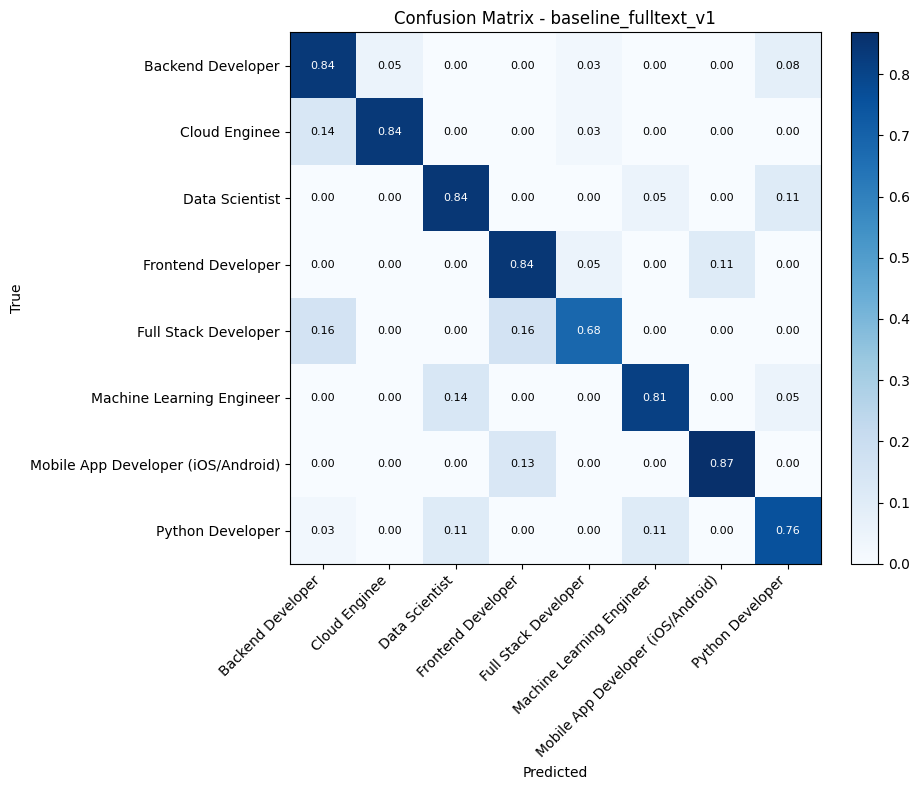


=== baseline_chunk_v1 ===
                                    precision    recall  f1-score   support

                 Backend Developer       0.41      0.84      0.55        37
                     Cloud Enginee       0.45      0.70      0.55        37
                    Data Scientist       0.43      0.53      0.47        38
                Frontend Developer       0.48      0.61      0.53        38
              Full Stack Developer       0.69      0.47      0.56        38
         Machine Learning Engineer       0.57      0.35      0.43        37
Mobile App Developer (iOS/Android)       0.71      0.26      0.38        38
                  Python Developer       0.88      0.19      0.31        37

                          accuracy                           0.49       300
                         macro avg       0.58      0.49      0.47       300
                      weighted avg       0.58      0.49      0.47       300

Tổng hợp: {'accuracy': 0.4933, 'precision_macro': 0.576, '

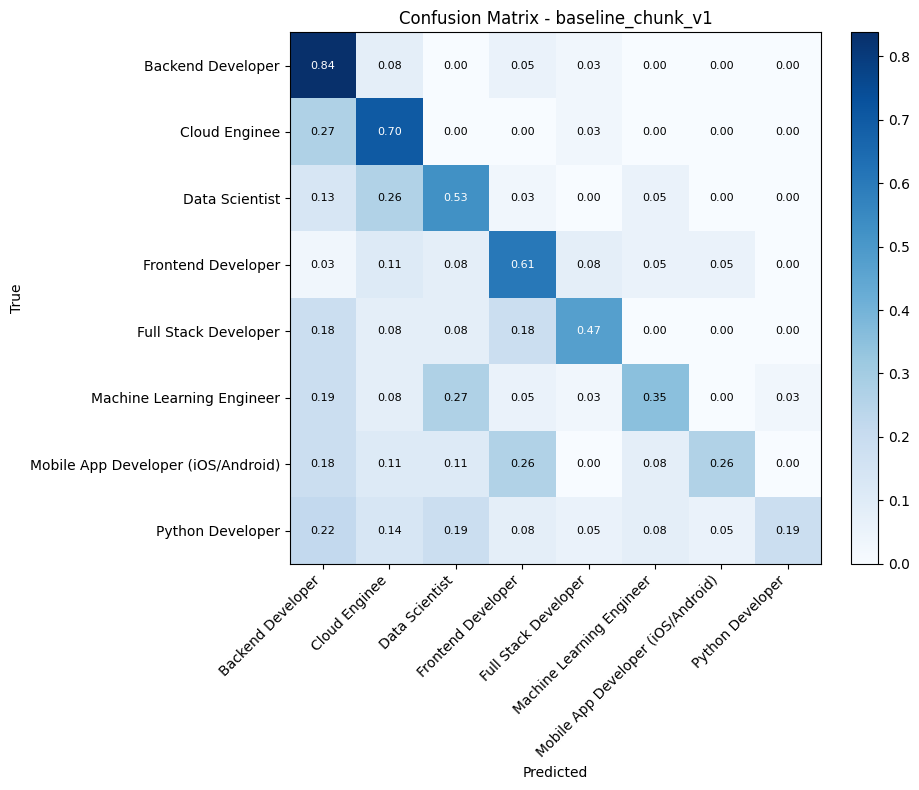


FULL-TEXT: {'accuracy': 0.81, 'precision_macro': 0.8167058339988005, 'recall_macro': 0.8100106685633002, 'f1_macro': 0.8105430965139707}

CHUNK-BASED: {'accuracy': 0.49333333333333335, 'precision_macro': 0.5759599972961387, 'recall_macro': 0.4936877667140825, 'f1_macro': 0.4741340965885615}


In [12]:
from collections import Counter
from sklearn.metrics import accuracy_score

def make_tfidf_model():
    return make_pipeline(
        TfidfVectorizer(
            max_features=10000,
            ngram_range=(1, 2),
            sublinear_tf=True
        ),
        LogisticRegression(
            max_iter=1500,
            class_weight="balanced",
            random_state=42
        )
    )

def split_into_chunks(text, chunk_size=80):
    words = str(text).split()
    if not words:
        return [""]
    return [
        " ".join(words[i:i + chunk_size])
        for i in range(0, len(words), chunk_size)
    ]

def majority_vote(values):
    counts = Counter(values)
    max_count = max(counts.values())
    return sorted(
        [k for k, v in counts.items() if v == max_count]
    )[0]

def predict_by_chunks(model, df, text_col="clean_text"):
    predictions = []

    for text in df[text_col]:
        chunks = split_into_chunks(text, chunk_size=80)
        chunk_preds = model.predict(chunks)
        predictions.append(majority_vote(chunk_preds))

    return np.asarray(predictions)

baseline_full = make_tfidf_model()
baseline_full.fit(
    train_df["clean_text"].astype(str),
    train_df["label"].astype(str)
)

val_full_pred = baseline_full.predict(val_df["clean_text"].astype(str))
test_full_pred = baseline_full.predict(test_df["clean_text"].astype(str))

joblib.dump(
    baseline_full,
    "models/baseline_fulltext_v1.pkl"
)

train_chunks = []
train_chunk_labels = []

for _, row in train_df.iterrows():
    chunks = split_into_chunks(row["clean_text"], chunk_size=80)
    train_chunks.extend(chunks)
    train_chunk_labels.extend([row["label"]] * len(chunks))

baseline_chunk = make_tfidf_model()
baseline_chunk.fit(train_chunks, train_chunk_labels)

val_chunk_pred = predict_by_chunks(baseline_chunk, val_df)
test_chunk_pred = predict_by_chunks(baseline_chunk, test_df)

joblib.dump(
    baseline_chunk,
    "models/baseline_chunk_v1.pkl"
)

from evaluation import (
    evaluate_model,
    save_predictions,
    compare_models,
    plot_comparison
)

labels = sorted(train_df["label"].unique())

save_predictions(
    "results/baseline_fulltext_test_preds.csv",
    test_df["id"], test_df["label"], test_full_pred
)

save_predictions(
    "results/baseline_chunk_test_preds.csv",
    test_df["id"], test_df["label"], test_chunk_pred
)

full_metrics = evaluate_model(
    "baseline_fulltext_v1",
    test_df["label"],
    test_full_pred,
    labels=labels,
    out_dir="results"
)

chunk_metrics = evaluate_model(
    "baseline_chunk_v1",
    test_df["label"],
    test_chunk_pred,
    labels=labels,
    out_dir="results"
)

print("\nFULL-TEXT:", full_metrics)
print("\nCHUNK-BASED:", chunk_metrics)

## Dựng bộ v2 từ dữ liệu của Chi


In [13]:
import os, re
import numpy as np
import pandas as pd

def split_sentences(text):
    sents = [s.strip() for s in re.split(r'(?<=[.!?])\s+', str(text).strip()) if s.strip()]
    return sents if sents else [""]

def make_shifted(df, seed=42):
    rng = np.random.RandomState(seed)
    new_texts, evid = [], []
    for t in df["text_sequence"]:
        s = split_sentences(t)
        k = rng.randint(len(s))
        new_texts.append(" ".join(s[k:] + s[:k]))
        evid.append((len(s) - k) % len(s))
    out = df.copy()
    out["text_sequence"] = new_texts
    out["evid_pos"] = evid
    return out

missing = [f"data/{s}.csv" for s in ["train", "val", "test"] if not os.path.exists(f"data/{s}.csv")]
if missing:
    print("Thieu file cua Chi:", missing)
    print("Thu muc hien tai:", os.getcwd(), "| data/ co:", os.listdir("data") if os.path.exists("data") else "khong co thu muc data")
    print("-> Chep train.csv, val.csv, test.csv trong data/ cua file zip Chi vao thu muc data/ nay roi chay lai.")
    chi_src = None
else:
    chi_src = {s: pd.read_csv(f"data/{s}.csv") for s in ["train", "val", "test"]}
if chi_src is None:
    pass
elif not all({"text_sequence", "category", "label"} <= set(d.columns) for d in chi_src.values()):
    print("data/{train,val,test}.csv chua phai ban cua Chi (can cot text_sequence, category, label).")
else:
    os.makedirs("data/v2", exist_ok=True)
    for (name, d), seed in zip(chi_src.items(), [1, 2, 3]):
        v2_df = make_shifted(d, seed)
        v2_df["clean_text"] = v2_df["text_sequence"]
        v2_df.to_csv(f"data/v2/{name}.csv", index=False)
    print("Da luu data/v2/{train,val,test}.csv | phan bo evid_pos (test v2):",
          np.bincount(pd.read_csv("data/v2/test.csv")["evid_pos"]).tolist())
    print("Doi chieu voi notebook cua Chi: [50, 36, 47, 41, 35, 41, 28, 22]")

Da luu data/v2/{train,val,test}.csv | phan bo evid_pos (test v2): [50, 36, 47, 41, 35, 41, 28, 22]
Doi chieu voi notebook cua Chi: [50, 36, 47, 41, 35, 41, 28, 22]


In [14]:
v2_dir = "data/v2"
v2_paths = {
    "train": os.path.join(v2_dir, "train.csv"),
    "val": os.path.join(v2_dir, "val.csv"),
    "test": os.path.join(v2_dir, "test.csv")
}

if not all(os.path.exists(p) for p in v2_paths.values()):
    print("Chua co du bo train/val/test trong data/v2/")
    print("Cac file dang co:", glob.glob("data/v2/*.csv"))
else:
    v2 = {
        name: pd.read_csv(path).fillna("")
        for name, path in v2_paths.items()
    }

    for name, df in v2.items():
        required = {"label", "clean_text"}
        missing = required - set(df.columns)
        if missing:
            raise ValueError(
                f"data/v2/{name}.csv thieu cot {sorted(missing)}"
            )

        if "id" not in df.columns:
            df["id"] = np.arange(len(df))

    train_texts = set(v2["train"]["clean_text"].astype(str))
    val_texts = set(v2["val"]["clean_text"].astype(str))
    test_texts = set(v2["test"]["clean_text"].astype(str))

    print("Overlap train-val:", len(train_texts & val_texts))
    print("Overlap train-test:", len(train_texts & test_texts))
    print("Overlap val-test:", len(val_texts & test_texts))

    if (
        train_texts & val_texts
        or train_texts & test_texts
        or val_texts & test_texts
    ):
        raise ValueError(
            "Phat hien van ban trung giua cac tap v2. "
            "Can xu ly truoc khi danh gia."
        )

    v2_train = v2["train"]
    v2_val = v2["val"]
    v2_test = v2["test"]

    v2_labels = sorted(v2_train["label"].unique())

    v2_full = make_tfidf_model()
    v2_full.fit(
        v2_train["clean_text"].astype(str),
        v2_train["label"]
    )

    v2_full_pred = v2_full.predict(
        v2_test["clean_text"].astype(str)
    )

    v2_train_chunks = []
    v2_train_chunk_labels = []

    for _, row in v2_train.iterrows():
        chunks = split_into_chunks(row["clean_text"], 80)
        v2_train_chunks.extend(chunks)
        v2_train_chunk_labels.extend([row["label"]] * len(chunks))

    v2_chunk = make_tfidf_model()
    v2_chunk.fit(v2_train_chunks, v2_train_chunk_labels)

    v2_chunk_pred = predict_by_chunks(v2_chunk, v2_test)

    joblib.dump(v2_full, "models/baseline_fulltext_v2.pkl")
    joblib.dump(v2_chunk, "models/baseline_chunk_v2.pkl")

    save_predictions(
        "results/baseline_fulltext_v2_test_preds.csv",
        v2_test["id"], v2_test["label"], v2_full_pred
    )

    save_predictions(
        "results/baseline_chunk_v2_test_preds.csv",
        v2_test["id"], v2_test["label"], v2_chunk_pred
    )

    v2_results = {
        "TF-IDF Full-text v2": (
            v2_test["label"], v2_full_pred
        ),
        "TF-IDF Chunk v2": (
            v2_test["label"], v2_chunk_pred
        )
    }

    v2_comparison = compare_models(v2_results)
    v2_comparison.to_csv(
        "results/baseline_comparison_v2.csv"
    )

    print(v2_comparison.round(4))

Overlap train-val: 0
Overlap train-test: 0
Overlap val-test: 0
                     accuracy  precision_macro  recall_macro  f1_macro
TF-IDF Full-text v2      0.81           0.8165          0.81    0.8105
TF-IDF Chunk v2          0.78           0.8086          0.78    0.7787


## Module đánh giá & so sánh hiệu năng (task Vinh)


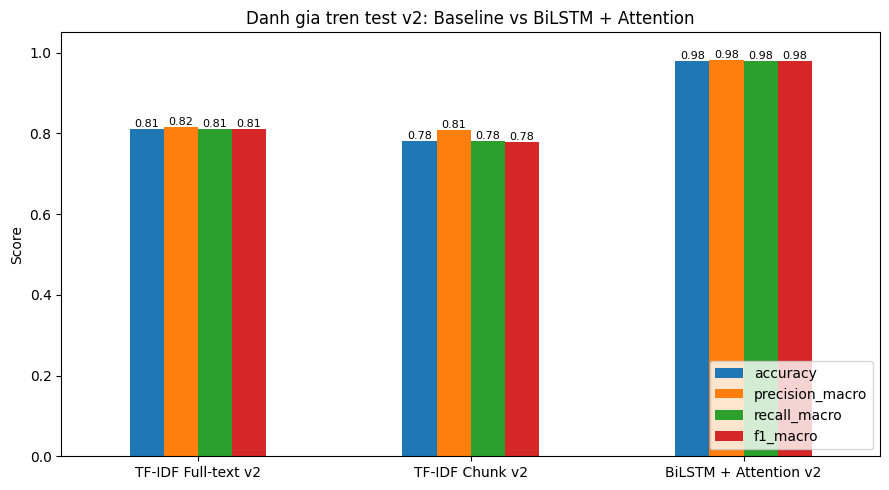

                       accuracy  precision_macro  recall_macro  f1_macro
TF-IDF Full-text v2        0.81           0.8165        0.8100    0.8105
TF-IDF Chunk v2            0.78           0.8086        0.7800    0.7787
BiLSTM + Attention v2      0.98           0.9807        0.9799    0.9801

=== final_v2_TF-IDF_Full-text_v2 ===
              precision    recall  f1-score   support

           0       0.74      0.84      0.78        37
           1       0.94      0.84      0.89        37
           2       0.76      0.84      0.80        38
           3       0.74      0.84      0.79        38
           4       0.87      0.68      0.76        38
           5       0.83      0.81      0.82        37
           6       0.89      0.87      0.88        38
           7       0.76      0.76      0.76        37

    accuracy                           0.81       300
   macro avg       0.82      0.81      0.81       300
weighted avg       0.82      0.81      0.81       300

Tổng hợp: {'accurac

In [15]:
import os
import pandas as pd
from evaluation import (load_predictions, compare_models, plot_comparison,
                        evaluate_model, per_class_report, most_confused_pairs)

V2_PRED_PATHS = {
    "TF-IDF Full-text v2": "results/baseline_fulltext_v2_test_preds.csv",
    "TF-IDF Chunk v2": "results/baseline_chunk_v2_test_preds.csv",
}
CHI_V2_PATH = "results/test_predictions_v2.csv"

v2_model_preds = {}
for name, path in V2_PRED_PATHS.items():
    if os.path.exists(path):
        v2_model_preds[name] = load_predictions(path).sort_values("id").reset_index(drop=True)
    else:
        print(f"Chua co {path} -> hay chay cell baseline v2 truoc.")

if os.path.exists(CHI_V2_PATH):
    v2_model_preds["BiLSTM + Attention v2"] = (
        load_predictions(CHI_V2_PATH).sort_values("id").reset_index(drop=True))
else:
    print(f"Chua co {CHI_V2_PATH} -> tam thoi chi so sanh cac baseline v2.")

if len(v2_model_preds) >= 1:
    ref_name = list(v2_model_preds)[0]
    ref = v2_model_preds[ref_name]
    for name, df in v2_model_preds.items():
        if not ref["id"].equals(df["id"]):
            raise ValueError(f"{name}: id khong khop voi {ref_name} (kiem tra cung tap test v2)")
        if not ref["y_true"].equals(df["y_true"]):
            raise ValueError(f"{name}: nhan that khong khop voi {ref_name}")

    v2_eval_labels = sorted(ref["y_true"].unique())
    final_v2 = compare_models({n: (d["y_true"], d["y_pred"]) for n, d in v2_model_preds.items()})
    final_v2.round(4).to_csv("results/final_comparison_v2.csv")
    plot_comparison(final_v2, title="Danh gia tren test v2: Baseline vs BiLSTM + Attention",
                    save_path="results/final_comparison_v2.png")
    print(final_v2.round(4))

    for name, df in v2_model_preds.items():
        tag = name.replace(" ", "_").replace("+", "plus")
        evaluate_model(f"final_v2_{tag}", df["y_true"], df["y_pred"],
                       labels=v2_eval_labels, out_dir="results", plot=False)
        most_confused_pairs(df["y_true"], df["y_pred"], v2_eval_labels, top_k=10).to_csv(
            f"results/final_v2_{tag}_confused_pairs.csv", index=False)